# Automated Waste Classification: Recyclable vs. Organic
**Framework:** TensorFlow/Keras

**Objective:**
 In this project, I will develop a robust binary classification model to distinguish between recyclable and organic waste using computer vision. This project utilizes Transfer Learning via a pre-trained VGG16 backbone, aggressive data augmentation to combat limited data, and a two-phase training approach (Feature Extraction followed by Fine-Tuning) to maximize accuracy.

In [ ]:
!pip install tensorflow==2.21.0 | tail -n 1
!pip install numpy | tail -n 1
!pip install scikit-learn==1.5.1  | tail -n 1
!pip install matplotlib==3.9.2  | tail -n 1

In [1]:
# Environment Setup & Imports
import os
import glob
import warnings
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from sklearn import metrics

# Suppress TensorFlow logging and generic warnings for cleaner output
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
warnings.filterwarnings('ignore')

# JAX requires ml_dtypes version 0.5 or newer, but 0.4.1 was installed
%pip install "ml_dtypes>=0.5.0" --upgrade --quiet

import tensorflow as tf
from tensorflow.keras.applications import VGG16
from tensorflow.keras.models import Model, Sequential
from tensorflow.keras.layers import Dense, Dropout, Flatten
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, LearningRateScheduler

# Verify hardware acceleration
print(f"TensorFlow Version: {tf.__version__}")
print("GPU Available: ", tf.config.list_physical_devices('GPU'))

TensorFlow Version: 2.17.0
GPU Available:  []


In [ ]:
# Add your own waste-classification dataset before retraining.
# Required folders: waste_dataset/train/O, waste_dataset/train/R,
#                   waste_dataset/test/O,  waste_dataset/test/R

dataset_root = Path("waste_dataset")
required_dirs = [
    dataset_root / "train" / "O",
    dataset_root / "train" / "R",
    dataset_root / "test" / "O",
    dataset_root / "test" / "R",
]
missing_dirs = [str(folder) for folder in required_dirs if not folder.is_dir()]
if missing_dirs:
    raise FileNotFoundError(
        "Please add your own appropriately licensed dataset under `waste_dataset/` "
        "with train/O, train/R, test/O, and test/R folders. Missing: "
        + ", ".join(missing_dirs)
    )

print(f"Using local dataset at: {dataset_root.resolve()}")


In [5]:
# Set up global variables so I can easily adjust them later if needed
img_rows, img_cols = 150, 150
batch_size = 32
n_epochs = 10
n_classes = 2
val_split = 0.2
path = str(dataset_root / 'train') + '/'
path_test = str(dataset_root / 'test') + '/'
input_shape = (img_rows, img_cols, 3)
labels = ['O', 'R'] # where O = Organic, R = Recyclable
seed = 42

In [6]:
# Create the training generator with data augmentation to prevent overfitting
train_datagen = ImageDataGenerator(
    validation_split = val_split,
    rescale=1.0/255.0,
    width_shift_range=0.1,
    height_shift_range=0.1,
    horizontal_flip=True
)

# Validation and Test sets should only be rescaled, NEVER augmented
val_datagen = ImageDataGenerator(
    validation_split = val_split,
    rescale=1.0/255.0,
)

test_datagen = ImageDataGenerator(
    rescale=1.0/255.0
)

# Connect the generators to the physical folders
train_generator = train_datagen.flow_from_directory(
    directory = path,
    seed = seed,
    batch_size = batch_size,
    class_mode='binary', # Using binary because it's only Organic vs Recyclable
    shuffle = True,
    target_size=(img_rows, img_cols),
    subset = 'training'
)

val_generator = val_datagen.flow_from_directory(
    directory = path,
    seed = seed,
    batch_size = batch_size,
    class_mode='binary',
    shuffle = True,
    target_size=(img_rows, img_cols),
    subset = 'validation'
)

# We keep shuffle=False for the test set so we can evaluate predictions properly
test_generator = test_datagen.flow_from_directory(
    directory=path_test,
    class_mode='binary',
    seed=seed,
    batch_size=batch_size,
    shuffle=False,
    target_size=(img_rows, img_cols)
)

Found 800 images belonging to 2 classes.
Found 200 images belonging to 2 classes.
Found 200 images belonging to 2 classes.


In [ ]:
# lets take a look at a few augemented  images beofre proceeding the module training
IMG_DIM = (100, 100)

train_files = glob.glob(str(Path(path) / 'O' / '*'))
train_files = train_files[:20]
train_imgs = [tf.keras.preprocessing.image.img_to_array(tf.keras.preprocessing.image.load_img(img, target_size=IMG_DIM)) for img in train_files]
train_imgs = np.array(train_imgs)
train_labels = [Path(fn).parent.name for fn in train_files]

img_id = 0
O_generator = train_datagen.flow(train_imgs[img_id:img_id+1], train_labels[img_id:img_id+1],
                                   batch_size=1)
O = [next(O_generator) for i in range(0,5)]
fig, ax = plt.subplots(1,5, figsize=(16, 6))
print('Labels:', [item[1][0] for item in O])
l = [ax[i].imshow(O[i][0][0]) for i in range(0,5)]


In [9]:
# I then load the pre trained VGG16 model, dropping the original top classification layers
vgg = VGG16(include_top=False, weights='imagenet', input_shape=input_shape)

# Flatten the output of the VGG base so we can attach our custom Dense layers
output = vgg.layers[-1].output
output = tf.keras.layers.Flatten()(output)
basemodel = Model(vgg.input, output)

# Freeze the VGG16 base layers to retain their ImageNet knowledge
for layer in basemodel.layers:
    layer.trainable = False

# Build our custom classifier on top of the frozen base
model = Sequential()
model.add(basemodel)
model.add(Dense(512, activation='relu'))
model.add(Dropout(0.3))
model.add(Dense(512, activation='relu'))
model.add(Dropout(0.3))
model.add(Dense(1, activation='sigmoid'))

model.summary()

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ functional (Functional)         │ (None, 8192)           │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │     4,194,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 512)            │       262,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │           513 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 19,172,673 (73.14 MB)

 Trainable params: 4,457,985 (17.01 MB)

 Non-trainable params: 14,714,688 (56.13 MB)

In [10]:
# Compile the model for our initial training phase
model.compile(
    loss='binary_crossentropy',
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    metrics=['accuracy']
)

# Define a custom learning rate decay to slow down as we get closer to the optimal weights
def exp_decay(epoch):
    initial_lrate = 1e-4
    k = 0.1
    lrate = initial_lrate * np.exp(-k*epoch)
    return lrate

class LossHistory_(tf.keras.callbacks.Callback):
    def on_train_begin(self, logs={}):
        self.losses = []
        self.lr = []

    def on_epoch_end(self, epoch, logs={}):
        self.losses.append(logs.get('loss'))
        self.lr.append(exp_decay(epoch))

checkpoint_path = 'O_R_tlearn_vgg16.keras'

# Callbacks to stop training early if it stops improving, saving the best version
keras_callbacks = [
      EarlyStopping(monitor='val_loss', patience=4, mode='min', min_delta=0.01),
      ModelCheckpoint(checkpoint_path, monitor='val_loss', save_best_only=True, mode='min')
]

callbacks_list_ = [LossHistory_(), LearningRateScheduler(exp_decay)] + keras_callbacks

# Start Phase 1 training
extract_feat_model = model.fit(
    train_generator,
    steps_per_epoch=5,
    epochs=10,
    callbacks=callbacks_list_,
    validation_data=val_generator,
    validation_steps=val_generator.samples // batch_size,
    verbose=1
)

Epoch 1/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 107s 24s/step - accuracy: 0.4938 - loss: 0.7737 - val_accuracy: 0.6979 - val_loss: 0.5969 - learning_rate: 1.0000e-04
Epoch 2/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 148s 34s/step - accuracy: 0.6250 - loss: 0.6480 - val_accuracy: 0.7812 - val_loss: 0.5253 - learning_rate: 9.0484e-05
Epoch 3/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 136s 31s/step - accuracy: 0.7375 - loss: 0.5621 - val_accuracy: 0.7552 - val_loss: 0.5027 - learning_rate: 8.1873e-05
Epoch 4/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 142s 33s/step - accuracy: 0.7312 - loss: 0.5475 - val_accuracy: 0.7396 - val_loss: 0.4939 - learning_rate: 7.4082e-05
Epoch 5/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 141s 33s/step - accuracy: 0.8313 - loss: 0.4548 - val_accuracy: 0.8177 - val_loss: 0.4287 - learning_rate: 6.7032e-05
Epoch 6/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 103s 23s/step - accuracy: 0.7875 - loss: 0.4536 - val_accuracy: 0.8333 - val_loss: 0.3993 - learning_rate: 6.0653e-05
Epoch 7/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 105s 24s/step - accuracy: 0.8062 - loss:

In [12]:
# Unfreeze the specific block5_conv3 layer of VGG16 to fine-tune it on our waste images
set_trainable = False
for layer in basemodel.layers:
    if layer.name in ['block5_conv3']:
        set_trainable = True
    if set_trainable:
        layer.trainable = True
    else:
        layer.trainable = False

# Re-compile with an even smaller learning rate so we don't destroy the pre-trained weights
model.compile(
    loss='binary_crossentropy',
    optimizer=tf.keras.optimizers.RMSprop(learning_rate=1e-4),
    metrics=['accuracy']
)

checkpoint_path_ft = 'O_R_tlearn_fine_tune_vgg16.keras'

keras_callbacks_ft = [
      EarlyStopping(monitor='val_loss', patience=4, mode='min', min_delta=0.01),
      ModelCheckpoint(checkpoint_path_ft, monitor='val_loss', save_best_only=True, mode='min')
]

callbacks_list_ft = [LossHistory_(), LearningRateScheduler(exp_decay)] + keras_callbacks_ft

# Start Phase 2 training
fine_tune_model = model.fit(
    train_generator,
    steps_per_epoch=5,
    epochs=10,
    callbacks=callbacks_list_ft,
    validation_data=val_generator,
    validation_steps=val_generator.samples // batch_size,
    verbose=1
)

Epoch 1/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 108s 24s/step - accuracy: 0.6875 - loss: 0.7417 - val_accuracy: 0.8542 - val_loss: 0.3412 - learning_rate: 1.0000e-04
Epoch 2/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 141s 33s/step - accuracy: 0.7875 - loss: 0.4476 - val_accuracy: 0.7812 - val_loss: 0.4048 - learning_rate: 9.0484e-05
Epoch 3/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 106s 24s/step - accuracy: 0.8687 - loss: 0.3444 - val_accuracy: 0.8229 - val_loss: 0.3574 - learning_rate: 8.1873e-05
Epoch 4/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 143s 33s/step - accuracy: 0.8625 - loss: 0.3066 - val_accuracy: 0.8750 - val_loss: 0.2847 - learning_rate: 7.4082e-05
Epoch 5/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 104s 24s/step - accuracy: 0.8438 - loss: 0.3724 - val_accuracy: 0.8490 - val_loss: 0.3151 - learning_rate: 6.7032e-05
Epoch 6/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 106s 24s/step - accuracy: 0.9187 - loss: 0.2345 - val_accuracy: 0.8333 - val_loss: 0.3260 - learning_rate: 6.0653e-05
Epoch 7/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 142s 33s/step - accuracy: 0.9125 - loss:

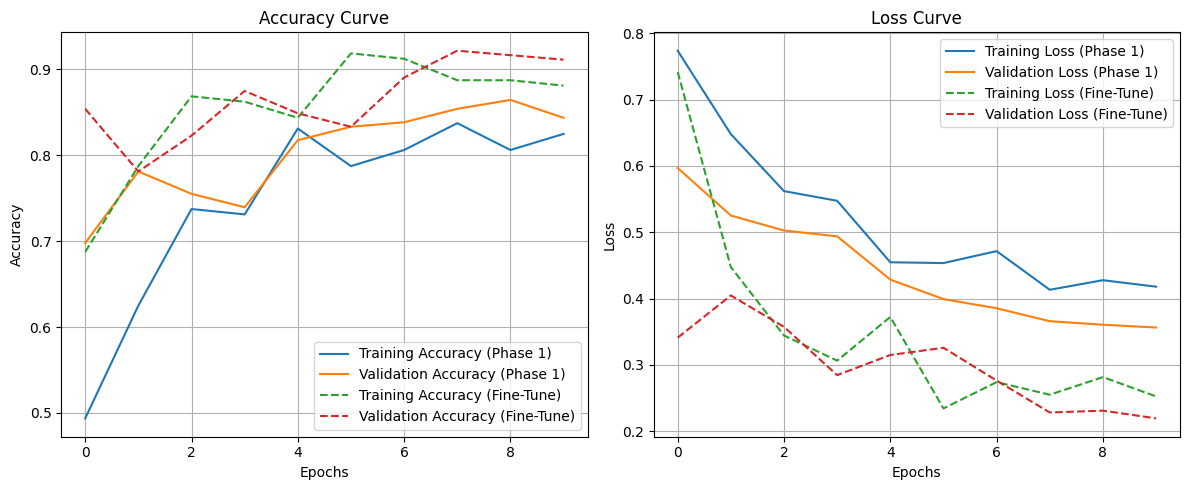

In [13]:
# Plot the accuracy and loss curves for both phases of training
plt.figure(figsize=(12, 5))

# Plot Accuracy
plt.subplot(1, 2, 1)
plt.plot(extract_feat_model.history['accuracy'], label='Training Accuracy (Phase 1)')
plt.plot(extract_feat_model.history['val_accuracy'], label='Validation Accuracy (Phase 1)')
plt.plot(fine_tune_model.history['accuracy'], label='Training Accuracy (Fine-Tune)', linestyle='--')
plt.plot(fine_tune_model.history['val_accuracy'], label='Validation Accuracy (Fine-Tune)', linestyle='--')
plt.title('Accuracy Curve')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

# Plot Loss
plt.subplot(1, 2, 2)
plt.plot(extract_feat_model.history['loss'], label='Training Loss (Phase 1)')
plt.plot(extract_feat_model.history['val_loss'], label='Validation Loss (Phase 1)')
plt.plot(fine_tune_model.history['loss'], label='Training Loss (Fine-Tune)', linestyle='--')
plt.plot(fine_tune_model.history['val_loss'], label='Validation Loss (Fine-Tune)', linestyle='--')
plt.title('Loss Curve')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [ ]:
# Load the test images and standardize them
IMG_DIM = (150, 150)
test_files_O = glob.glob(str(Path(path_test) / 'O' / '*'))
test_files_R = glob.glob(str(Path(path_test) / 'R' / '*'))
test_files = test_files_O[:50] + test_files_R[:50]

test_imgs = [tf.keras.preprocessing.image.img_to_array(tf.keras.preprocessing.image.load_img(img, target_size=IMG_DIM)) for img in test_files]
test_imgs = np.array(test_imgs)
test_labels = [Path(fn).parent.name for fn in test_files] # Extracts 'O' or 'R'

test_imgs_scaled = test_imgs.astype('float32') / 255.0

# Evaluate the final fine-tuned model once on the held-out test images
probabilities = model.predict(test_imgs_scaled, verbose=0).flatten()
predictions = ['O' if p < 0.5 else 'R' for p in probabilities]

print('Fine-Tuned Model Results:')
print(metrics.classification_report(test_labels, predictions))

In [ ]:
# Helper function to plot a single image alongside its actual and predicted labels
def plot_image_with_title(image, model_name, actual_label, predicted_label):
    plt.imshow(image)
    plt.title(f"Model: {model_name}\nActual: {actual_label} | Predicted: {predicted_label}")
    plt.axis('off')
    plt.show()

# We will look at the image at index 1 as requested in the instructions
index_to_plot = 1

# --- Task 9: Plot using Extract Features Model ---
plot_image_with_title(
    image=test_imgs[index_to_plot].astype('uint8'),
    model_name='Extract Features Model',
    actual_label=test_labels[index_to_plot],
    predicted_label=predictions_extract[index_to_plot]
)

# --- Task 10: Plot using Fine-Tuned Model ---
plot_image_with_title(
    image=test_imgs[index_to_plot].astype('uint8'),
    model_name='Fine-Tuned Model',
    actual_label=test_labels[index_to_plot],
    predicted_label=predictions_fine[index_to_plot]
)